In [108]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import matplotlib.pyplot as plt
import scipy as sp
from scipy.odr import *
import random
import operator

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
from statsmodels.formula.api import wls
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

In [109]:
def calc_rms (data_set):
    sum_of_squares = 0
    for i in range(0,len(data_set)):
        sum_of_squares = sum_of_squares + data_set[i]**2
    rms = np.sqrt(sum_of_squares/len(data_set))
    return rms

def calc_rms_error (predicted_data, obsv_data):
    sum_of_squares_of_error = 0
    if len(predicted_data) != len(obsv_data):
        print ('Warning! Data Sets of Unequal Size! Calculation is invalid!')
    for i in range(0,len(predicted_data)):
        sum_of_squares_of_error = sum_of_squares_of_error + (predicted_data[i] - obsv_data[i])**2
    ms_error = sum_of_squares_of_error/len(predicted_data)
    rms_error = np.sqrt(ms_error)
    return rms_error
    
lum_limits=(2.8,4.5)
per_limits=(1.2,3)
mass_limits=(np.log(0.5),np.log(5))
Q_limits=(-0.65,1.45)
mdot_limits=(-9,-4)
resid_limits=(-3,3)

In [110]:
M0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundMStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip
M1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneMStarData.csv',delimiter=',',skip_header=1))) # Has header, so skip
C0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundamentalCStarData.csv',delimiter=',',skip_header=1))) # Has header, so skip
C1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneCStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip

In [111]:
MdotIndex=5 # Column of imported files that has Mdot data
MdotErrorIndex=6 # Absolute error in Mdot
#MdotIndex=2 # Column of imported files that has Mdot_dust Data
LIndex=8 # Column of imported files that has LBol data
LErrorIndex=9 # Absolute error in L
PIndex=13 # Column of imported files that has Period data
MIndex=22 # Column of imported files that has Mass data
RIndex=23 # Column of imported files that has Radius data
TeffObsvIndex=12 # Column of imported files that has Observed Teff Data
TeffCalcIndex=24 # Column of imported files that has Calculated Teff Data

In [112]:
DataToFit=M0StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.
# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])

In [113]:
def CriticalZoneOnly (DataToTrim,logLowerBound,logUpperBound): # Function to restrict an imported data set
    # to only stars in the critical mass loss range
    CuttingArray = []
    i = 0
    Cleaned_Set = np.transpose(DataToTrim)
    while i<len(DataToTrim[MdotIndex]):
        if np.log10(DataToTrim[MdotIndex][i]) < logLowerBound: # If logMdot is lesser than the declared lower bound
            CuttingArray.append(i) # Add this row to the list of rows to be cut
        elif np.log10(DataToTrim[MdotIndex][i]) > logUpperBound: # If logMdot is greater than the declared upper bound
            CuttingArray.append(i) # Add this row to the list of rows to be cut
        i += 1 # Move to the next row
    Cleaned_Set = np.delete(Cleaned_Set,CuttingArray,axis=0)
    print ('Entries Removed:',len(CuttingArray))
    print ('Stars Remaining:', len(Cleaned_Set))
    return np.transpose(Cleaned_Set)

In [114]:
def examine_index(elem): 
    # Sorting Key. Will sort a list based on the specified index hard coded here.
    return elem[MdotIndex]
def sort_star_data(DataToSort):
    TransposedArray=np.transpose(DataToSort)
    TempList=TransposedArray.tolist()
    TempList=sorted(TempList,key = operator.itemgetter(MdotIndex))
    return np.transpose(np.asarray(TempList))

In [115]:
sort_star_data(DataToFit)[MdotIndex]

array([7.05804176e-09, 8.32848928e-09, 8.75197179e-09, ...,
       3.24669921e-06, 3.38786005e-06, 3.52902088e-06])

In [116]:
def MassRangeSelect (DataToTrim, LowerBound, UpperBound ):
    return np.transpose(np.transpose(sort_star_data(DataToTrim))[LowerBound-1:UpperBound-1])

In [117]:
MassRangeSelect (DataToFit,780,1171)

array([[           nan,            nan,            nan, ...,
                   nan,            nan,            nan],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [1.00000000e-10, 1.00000000e-10, 1.00000000e-10, ...,
        1.50000000e-10, 1.50000000e-10, 1.50000000e-10],
       ...,
       [7.36000000e+00, 3.11000000e+00, 2.95000000e+00, ...,
        3.84000000e+00, 1.23000000e+01, 6.67000000e+00],
       [1.47312250e+00, 1.78262920e+00, 1.49106086e+00, ...,
        1.25857281e+00, 1.87056030e+00, 1.60889984e+00],
       [2.24586815e+02, 1.72678554e+02, 2.23746252e+02, ...,
        1.56893611e+02, 2.55683978e+02, 2.29925820e+02]])

# (P/L^W), M fits

## M0 Stars

In [118]:
DataToFit=M0StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.
#DataToFit = CriticalZoneOnly(DataToFit,-7,-6)
Percentile40th = int(np.floor(0.4*len(np.transpose(DataToFit))))
Percentile60th = int(np.ceil(0.6*len(np.transpose(DataToFit))))
print('40th Percentile:', Percentile40th,'60th Percentile:', Percentile60th)
DataToFit = MassRangeSelect (DataToFit, Percentile40th, Percentile60th )
# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logLDataError = np.log10(DataToFit[LErrorIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotDataError = np.log10(DataToFit[MdotErrorIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])
#WRatio = 0.6741 # 1.5 gave better fit, but unrealisitc exponents. Taking Lee Anne's value as independent
#WRatio = 1.15020259478
#logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio)) # log (P/(L^W))

40th Percentile: 780 60th Percentile: 1171


In [119]:
# logP ~ V + W log L

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLData
y = logPData

data = pandas.DataFrame({'logL': x0, 'logP': y})

# Fit the model
model = wls("logP ~ logL", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            WLS Regression Results                            
Dep. Variable:                   logP   R-squared:                       0.654
Model:                            WLS   Adj. R-squared:                  0.653
Method:                 Least Squares   F-statistic:                     736.3
Date:                Sat, 07 Nov 2020   Prob (F-statistic):           9.29e-92
Time:                        19:18:10   Log-Likelihood:                 470.32
No. Observations:                 391   AIC:                            -936.6
Df Residuals:                     389   BIC:                            -928.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.2176      0.090     -2.413      0.0

In [120]:
V = model._results.params[0]
WRatio = model._results.params[1]
print('W=',WRatio)
logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio)) # log (P/(L^W))

W= 0.6830057183526329


logP= -0.21758717714637626 + 0.6830057183526329 logL


Text(0.5, 1.0, 'M0 - logP = V + W logL')

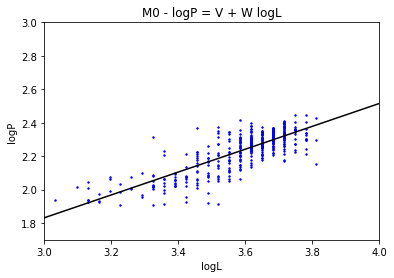

In [121]:
print('logP=', V, '+', WRatio, 'logL')
plot.scatter(logLData,logPData,s=2,color='blue')
coordinate_list = np.asarray([3,3.5,4])
logLvlogP_predict=V + WRatio *coordinate_list
plot.plot(coordinate_list,logLvlogP_predict, color='black')
plot.xlabel("logL")
plot.ylabel("logP")
plot.xlim(coordinate_list[0], coordinate_list[-1])
plot.ylim(1.7, 3)
plot.title('M0 - logP = V + W logL')

In [122]:
# Restore Unrestricted data so we can plot all of it, not just the data used to make our formula
DataToFit=M0StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.

# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logLDataError = np.log10(DataToFit[LErrorIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotDataError = np.log10(DataToFit[MdotErrorIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])
logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio)) # log (P/(L^W))

In [123]:
# logMdot ~ logA + c log((P/L)^W) + d logM

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPdivLWData
x1 = logMData
y = logMdotData

data = pandas.DataFrame({'logPdivLW': x0, 'logM': x1, 'logMdot': y})

# Fit the model
model = wls("logMdot ~ logPdivLW + logM", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            WLS Regression Results                            
Dep. Variable:                logMdot   R-squared:                       0.206
Model:                            WLS   Adj. R-squared:                  0.206
Method:                 Least Squares   F-statistic:                     253.3
Date:                Sat, 07 Nov 2020   Prob (F-statistic):           1.70e-98
Time:                        19:18:10   Log-Likelihood:                -711.19
No. Observations:                1951   AIC:                             1428.
Df Residuals:                    1948   BIC:                             1445.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -6.2307      0.026   -235.627      0.0

In [124]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logPdivLWData, logMData), y=logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[0]]) # Use the linear regression as an initial guess

# Run the regression.
outPdivLW_M = odr.run()

# Use the in-built pprint method to give us results.
outPdivLW_M.pprint()

Beta: [14.21686065  7.48975188 -3.81614491]
Beta Std Error: [0.7127949 0.4339006 0.1493728]
Beta Covariance: [[179.26900544 100.57000815  37.24556381]
 [100.57000815  66.42882086  20.77294439]
 [ 37.24556381  20.77294439   7.87261634]]
Residual Variance: 0.002834157318345672
Inverse Condition #: 0.01735314561475809
Reason(s) for Halting:
  Sum of squares convergence


In [125]:
logMdot_PdivLM = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2]
print( 'logMdot =', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM + ', outPdivLW_M.beta[2])

logMdot = 14.216860652255718 log(P/L^W) +  7.489751883786768 logM +  -3.816144909387197


In [126]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = logMdot_PdivLM

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_PdivLM': y})

# Fit the model
model = ols("logMdot_PdivLM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
PdivLMLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

Comparison to Observed: logMdot_calc = ( -0.12539009253942016 ) + ( 0.9814952846729118 )*logMdot_obsv


Text(0.5, 1.0, 'M0 - No Errors Included')

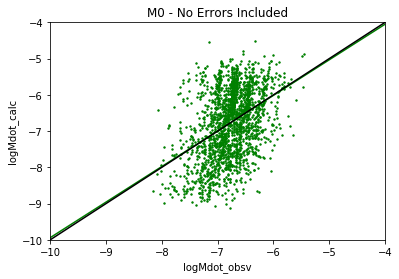

In [127]:
SlopeTestNoErrors=PdivLMLine[0] + PdivLMLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
print('Comparison to Observed:','logMdot_calc = (',PdivLMLine[0],') + (',PdivLMLine[1],')*logMdot_obsv')
plot.scatter(logMdotData, logMdot_PdivLM, s=2, color='green')
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('M0 - No Errors Included')

### Residuals

In [128]:
ResidualYAxis = logMdot_PdivLM - logMdotData # Calc - Obsv; Gives the distance between the regression line and the data
#ResidualYAxis = logMdot_PdivLM - ResidualYAxis # Subtract Residual from model
ylabel = 'First Residual' # What is on the y label until we change this value
star_type = 'M0'
PlotTitle = star_type + ' - No Errors Included' # Label the plot with whatever data set we are using

In [129]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPData
y = ResidualYAxis

data = pandas.DataFrame({'logPData': x0, 'ResidualYAxis': y})

# Fit the model
model = ols("ResidualYAxis ~ logPData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
ResidualsFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Residual Fit: logMdotCalc-logMdotObsv =', ResidualsFit[0], '+', ResidualsFit[1], 'logP')

Residual Fit: logMdotCalc-logMdotObsv = -12.751897087121566 + 5.810513694459377 logP


#### Plot Set: First Residual vs logP, logL, logQ, and logM

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -12.751897087121566 + 5.810513694459377 logP


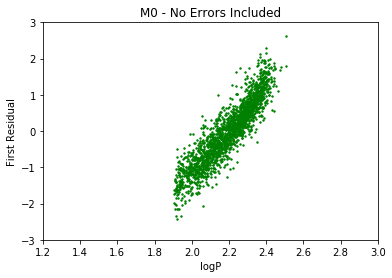

In [130]:
# NewlogMdotCalc - logMdotobs vs logP
xdataSet = logPData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logP')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logP")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(per_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_logP')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -12.180592895403855 + 3.453160001241986 logL


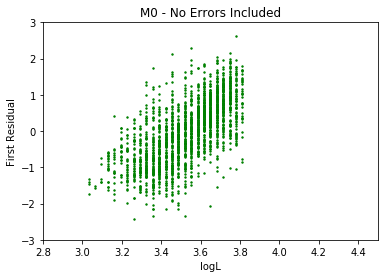

In [131]:
# NewlogMdotCalc - logMdotobs vs logL
xdataSet = logLData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logL')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logL")
plot.ylabel(ylabel)
plot.xlim(lum_limits)
plot.ylim(resid_limits)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_logL')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 1.2115958697518312 + 5.6460462138907666 logQ


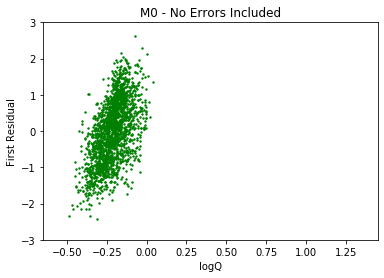

In [132]:
# NewlogMdotCalc - logMdotobs vs logQ (Q = (P/L^W))
logQData = np.log10(10**(logPData)/(10**(logLData))**(WRatio))

xdataSet = logQData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logQ')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logQ")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(Q_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_logQ')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -0.018588285133237306 + 1.526553717102509 logM


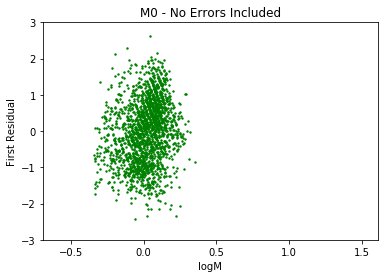

In [133]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logMData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logMData, ResidualYAxis, s=2, color='green')
plot.xlabel("logM")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(mass_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_logM')

In [134]:
NewMdotCalc = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2] - ResidualsFit[0] - ResidualsFit[1]*logPData
ylabel = "NewlogMdotCalc"
print('NewMdotCalc =', -ResidualsFit[0] + outPdivLW_M.beta[2], '+', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM - ', ResidualsFit[1], 'logP', '; W =', WRatio )

# Simplified statement: constants + A log P + B log L + log M

print('NewMdotCalc =', -ResidualsFit[0] + outPdivLW_M.beta[2], '+ (', outPdivLW_M.beta[0] - ResidualsFit[1],') logP + (', -1*outPdivLW_M.beta[0]*WRatio,') logL + ', outPdivLW_M.beta[1], 'logM'  )

NewMdotCalc = 8.935752177734368 + 14.216860652255718 log(P/L^W) +  7.489751883786768 logM -  5.810513694459377 logP ; W = 0.6830057183526329
NewMdotCalc = 8.935752177734368 + ( 8.406346957796341 ) logP + ( -9.710197122513199 ) logL +  7.489751883786768 logM


NewMdotCalc Fit: NewlogMdotCalc = -5.101674830654899 + 0.24707475055180006 logMdot_obsv


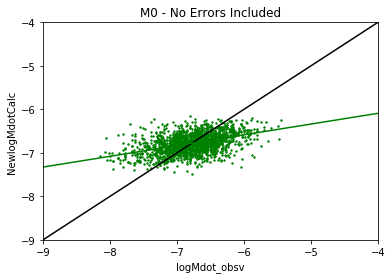

In [135]:
# logMdot ~ logM + logL + logP
xdataSet = logMdotData
# First we need to flatten the data: it's 2D layout is not relevent.
x0 = xdataSet
y = NewMdotCalc

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('NewMdotCalc Fit: NewlogMdotCalc =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logMdot_obsv')

plot.scatter(xdataSet, NewMdotCalc, s=2, color='green')
plot.plot(np.asarray([-9,-7,-6,-4]),np.asarray([-9,-7,-6,-4]),color='black')
SlopeTestNoErrors=NewMdotCalcFit[0] +NewMdotCalcFit[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.xlim(mdot_limits)
plot.ylim(mdot_limits)
plot.xlabel("logMdot_obsv")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/newMdot_vs_Mdotobsv')

Residuals Fit: OldResidual = -5.745950144837191e-06 + 1.000000000000002 NewResidual


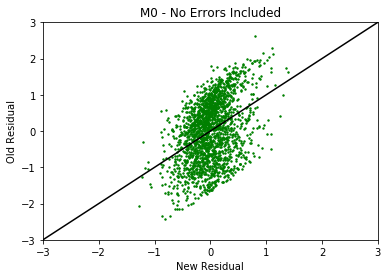

In [136]:
# 
NewResidual = NewMdotCalc - logMdotData # Calc - Obsv; Gives the distance between the regression line and the data
ylabel = 'Old Residual' # What is on the y label until we change this value

xdataSet = NewResidual
# First we need to flatten the data: it's 2D layout is not relevent.
x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Residuals Fit: OldResidual =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'NewResidual')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
SlopeTestNoErrors=NewMdotCalcFit[0] +NewMdotCalcFit[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.plot(np.asarray([-4,-1,0,1,4]),np.asarray([-4,-1,0,1,4]),color='black')
plot.xlim(resid_limits)
plot.ylim(resid_limits)
plot.xlabel("New Residual")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_second_resid')

In [137]:
### RMS of Data
RMSE = calc_rms_error (NewMdotCalc, logMdotData)
print ('RMS Error:', RMSE)
print ('STD Dev:', np.std(NewMdotCalc))

RMS Error: 0.3534974305174701
STD Dev: 0.2181605607721838


#### Plot Set: New Residual vs logP, logL, logQ, and logM

In [138]:
ylabel = 'New Residual'
ResidualYAxis = NewResidual

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 9.267760170406092e-15 + 3.649966613672451e-15 logP


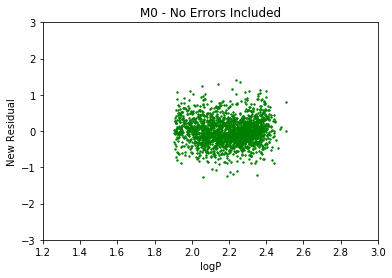

In [139]:
# NewlogMdotCalc - logMdotobs vs logP
xdataSet = logPData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logP')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logP")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(per_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logP')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 0.7984631822606671 + -0.2263619224275672 logL


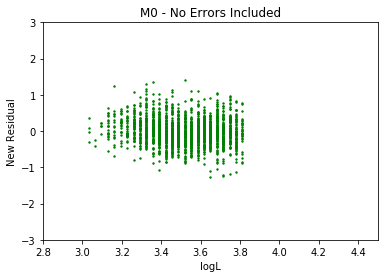

In [140]:
# NewlogMdotCalc - logMdotobs vs logL
xdataSet = logLData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logL')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logL")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(lum_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logL')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 0.1273567366698178 + 0.5934805727965369 logQ


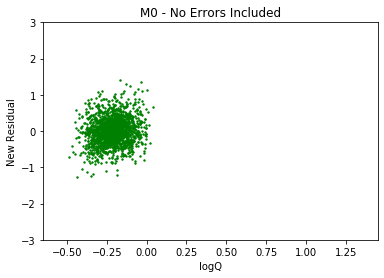

In [141]:
# NewlogMdotCalc - logMdotobs vs logQ (Q = (P/L^W))
logQData = np.log10(10**(logPData)/(10**(logLData))**(WRatio))

xdataSet = logQData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logQ')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlim(Q_limits)
plot.ylim(resid_limits)
plot.xlabel("logQ")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logQ')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 0.005888258764107748 + -0.4837198627705997 logM


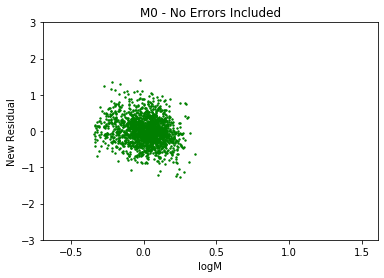

In [142]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logMData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logMData, ResidualYAxis, s=2, color='green')
plot.xlim(mass_limits)
plot.ylim(resid_limits)
plot.xlabel("logM")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logM')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -7.952874805771199 + 0.5379987865297048 logM


Text(0.5, 1.0, 'M0 - No Errors Included')

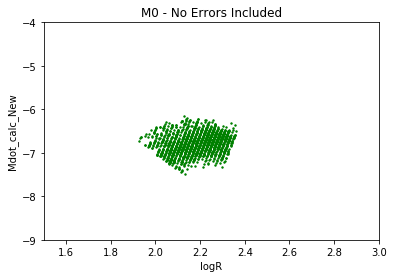

In [143]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logRData

x0 = xdataSet
y = NewMdotCalc

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logRData, NewMdotCalc, s=2, color='green')
plot.xlim(1.5,3)
plot.ylim(mdot_limits)
plot.xlabel("logR")
plot.ylabel('Mdot_calc_New')
plot.title(PlotTitle)
#plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logM')

In [144]:
len(NewMdotCalc)

1951

## M1 Stars

In [145]:
DataToFit=M1StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.
#DataToFit = CriticalZoneOnly(DataToFit,-7,-6)
Percentile40th = int(np.floor(0.4*len(np.transpose(DataToFit))))
Percentile60th = int(np.ceil(0.6*len(np.transpose(DataToFit))))
print('40th Percentile:', Percentile40th,'60th Percentile:', Percentile60th)
DataToFit = MassRangeSelect (DataToFit, Percentile40th, Percentile60th )
# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logLDataError = np.log10(DataToFit[LErrorIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotDataError = np.log10(DataToFit[MdotErrorIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])

40th Percentile: 864 60th Percentile: 1298


In [146]:
#logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio)) # log (P/(L^W))

# logP ~ V + W log L

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLData
y = logPData

data = pandas.DataFrame({'logL': x0, 'logP': y})

# Fit the model
model = wls("logP ~ logL", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            WLS Regression Results                            
Dep. Variable:                   logP   R-squared:                       0.846
Model:                            WLS   Adj. R-squared:                  0.845
Method:                 Least Squares   F-statistic:                     2366.
Date:                Sat, 07 Nov 2020   Prob (F-statistic):          2.25e-177
Time:                        19:18:13   Log-Likelihood:                 704.10
No. Observations:                 434   AIC:                            -1404.
Df Residuals:                     432   BIC:                            -1396.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.2391      0.045     -5.305      0.0

W= 0.61144119885264
logP= -0.2391417252487666 + 0.61144119885264 logL


Text(0.5, 1.0, 'M1 - logP = V + W logL')

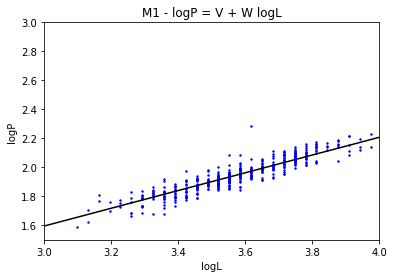

In [147]:
V = model._results.params[0]
WRatio = model._results.params[1]
print('W=',WRatio)
logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio)) # log (P/(L^W))

print('logP=', V, '+', WRatio, 'logL')
plot.scatter(logLData,logPData,s=2,color='blue')
coordinate_list = np.asarray([3,3.5,4])
logLvlogP_predict=V + WRatio *coordinate_list
plot.plot(coordinate_list,logLvlogP_predict, color='black')
plot.xlabel("logL")
plot.ylabel("logP")
plot.xlim(coordinate_list[0], coordinate_list[-1])
plot.ylim(1.5, 3)
plot.title('M1 - logP = V + W logL')

In [148]:
# Restore Unrestricted data so we can plot all of it, not just the data used to make our formula
DataToFit=M1StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.

# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logLDataError = np.log10(DataToFit[LErrorIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotDataError = np.log10(DataToFit[MdotErrorIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])
logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio)) # log (P/(L^W))

In [149]:
# logMdot ~ logA + c log((P/L)^W) + d logM

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPdivLWData
x1 = logMData
y = logMdotData

data = pandas.DataFrame({'logPdivLW': x0, 'logM': x1, 'logMdot': y})

# Fit the model
model = wls("logMdot ~ logPdivLW + logM", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            WLS Regression Results                            
Dep. Variable:                logMdot   R-squared:                       0.343
Model:                            WLS   Adj. R-squared:                  0.342
Method:                 Least Squares   F-statistic:                     563.4
Date:                Sat, 07 Nov 2020   Prob (F-statistic):          1.31e-197
Time:                        19:18:13   Log-Likelihood:                -855.24
No. Observations:                2162   AIC:                             1716.
Df Residuals:                    2159   BIC:                             1734.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -5.7774      0.038   -153.054      0.0

In [150]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logPdivLWData, logMData), y=logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[0]]) # Use the linear regression as an initial guess

# Run the regression.
outPdivLW_M = odr.run()

# Use the in-built pprint method to give us results.
outPdivLW_M.pprint()

logMdot_PdivLM = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2]
print( 'logMdot =', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM + ', outPdivLW_M.beta[2])


Beta: [14.55134625  4.10712704 -3.32707251]
Beta Std Error: [0.4581911  0.14793352 0.11355211]
Beta Covariance: [[121.56607121  27.24487519  29.91179278]
 [ 27.24487519  12.67220746   6.66258417]
 [ 29.91179278   6.66258417   7.46637021]]
Residual Variance: 0.0017269545913161117
Inverse Condition #: 0.023087903923678557
Reason(s) for Halting:
  Sum of squares convergence
logMdot = 14.551346249573244 log(P/L^W) +  4.1071270378651725 logM +  -3.3270725108168886


In [151]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = logMdot_PdivLM

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_PdivLM': y})

# Fit the model
model = ols("logMdot_PdivLM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
PdivLMLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

Comparison to Observed: logMdot_calc = ( -0.06055975654926449 ) + ( 0.9912260082453265 )*logMdot_obsv


Text(0.5, 1.0, 'M1 - No Errors Included')

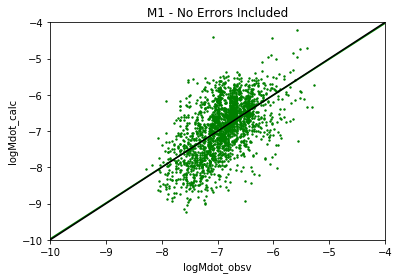

In [152]:
SlopeTestNoErrors=PdivLMLine[0] + PdivLMLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
print('Comparison to Observed:','logMdot_calc = (',PdivLMLine[0],') + (',PdivLMLine[1],')*logMdot_obsv')
plot.scatter(logMdotData, logMdot_PdivLM, s=2, color='green')
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('M1 - No Errors Included')

### Residuals

In [153]:
ResidualYAxis = logMdot_PdivLM - logMdotData # Calc - Obsv; Gives the distance between the regression line and the data
#ResidualYAxis = logMdot_PdivLM - ResidualYAxis # Subtract Residual from model
ylabel = 'First Residual' # What is on the y label until we change this value
star_type = 'M1'
PlotTitle = star_type + ' - No Errors Included' # Label the plot with whatever data set we are using

In [154]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPData
y = ResidualYAxis

data = pandas.DataFrame({'logPData': x0, 'ResidualYAxis': y})

# Fit the model
model = ols("ResidualYAxis ~ logPData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
ResidualsFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Residual Fit: logMdotCalc-logMdotObsv =', ResidualsFit[0], '+', ResidualsFit[1], 'logP')

Residual Fit: logMdotCalc-logMdotObsv = -5.550989878654154 + 2.856887752620167 logP


#### Plot Set: First Residual vs logP, logL, logQ, and logM

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -5.550989878654154 + 2.856887752620167 logP


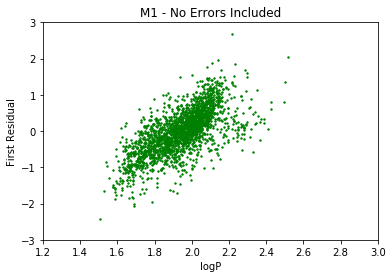

In [155]:
# NewlogMdotCalc - logMdotobs vs logP
xdataSet = logPData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logP')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logP")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(per_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_logP')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -4.735187090719776 + 1.3217614855691893 logL


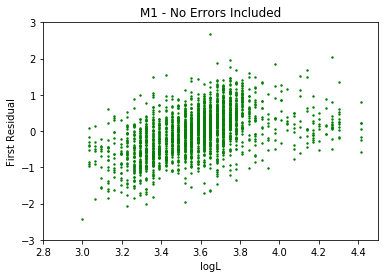

In [156]:
# NewlogMdotCalc - logMdotobs vs logL
xdataSet = logLData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logL')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logL")
plot.ylabel(ylabel)
plot.xlim(lum_limits)
plot.ylim(resid_limits)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_logL')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 1.8953472174636883 + 7.659289660126328 logQ


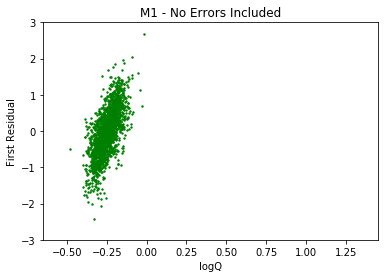

In [157]:
# NewlogMdotCalc - logMdotobs vs logQ (Q = (P/L^W))
logQData = np.log10(10**(logPData)/(10**(logLData))**(WRatio))

xdataSet = logQData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logQ')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logQ")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(Q_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_logQ')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -0.0027217856569324577 + 0.43461666276295274 logM


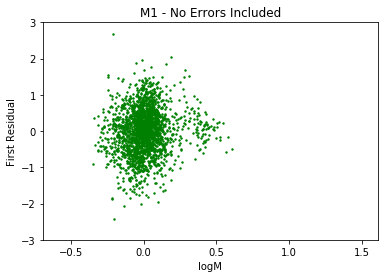

In [158]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logMData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logMData, ResidualYAxis, s=2, color='green')
plot.xlabel("logM")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(mass_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_logM')

In [159]:
NewMdotCalc = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2] - ResidualsFit[0] - ResidualsFit[1]*logPData
ylabel = "NewlogMdotCalc"
print('NewMdotCalc =', -ResidualsFit[0] + outPdivLW_M.beta[2], '+', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM - ', ResidualsFit[1], 'logP', '; W =', WRatio )
print('NewMdotCalc =', -ResidualsFit[0] + outPdivLW_M.beta[2], '+ (', outPdivLW_M.beta[0] - ResidualsFit[1],') logP + (', -1*outPdivLW_M.beta[0]*WRatio,') logL + ', outPdivLW_M.beta[1], 'logM'  )

NewMdotCalc = 2.2239173678372657 + 14.551346249573244 log(P/L^W) +  4.1071270378651725 logM -  2.856887752620167 logP ; W = 0.61144119885264
NewMdotCalc = 2.2239173678372657 + ( 11.694458496953077 ) logP + ( -8.897292595758932 ) logL +  4.1071270378651725 logM


NewMdotCalc Fit: NewlogMdotCalc = -3.893538052000105 + 0.43589806092615635 logMdot_obsv


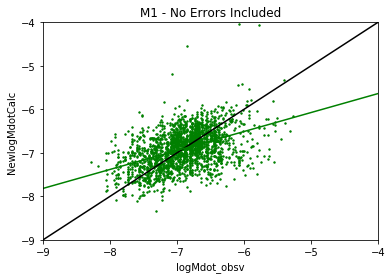

In [160]:
# logMdot ~ logM + logL + logP
xdataSet = logMdotData
# First we need to flatten the data: it's 2D layout is not relevent.
x0 = xdataSet
y = NewMdotCalc

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('NewMdotCalc Fit: NewlogMdotCalc =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logMdot_obsv')

plot.scatter(xdataSet, NewMdotCalc, s=2, color='green')
plot.plot(np.asarray([-9,-7,-6,-4]),np.asarray([-9,-7,-6,-4]),color='black')
SlopeTestNoErrors=NewMdotCalcFit[0] +NewMdotCalcFit[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.xlim(mdot_limits)
plot.ylim(mdot_limits)
plot.xlabel("logMdot_obsv")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/newMdot_vs_Mdotobsv')

Residuals Fit: OldResidual = -9.456670806672063e-09 + 1.0000000000000007 NewResidual


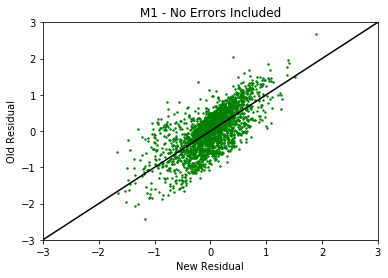

In [161]:
# 
NewResidual = NewMdotCalc - logMdotData # Calc - Obsv; Gives the distance between the regression line and the data
ylabel = 'Old Residual' # What is on the y label until we change this value

xdataSet = NewResidual
# First we need to flatten the data: it's 2D layout is not relevent.
x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Residuals Fit: OldResidual =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'NewResidual')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.plot(np.asarray([-4,-1,0,1,4]),np.asarray([-4,-1,0,1,4]),color='black')
plot.xlim(resid_limits)
plot.ylim(resid_limits)
plot.xlabel("New Residual")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_second_resid')

In [162]:
### RMS of Data
RMSE = calc_rms_error (NewMdotCalc, logMdotData)
print ('RMS Error:', RMSE)
print ('STD Dev:', np.std(NewMdotCalc))

RMS Error: 0.45522003645521025
STD Dev: 0.4266439014864354


#### Plot Set: New Residual vs logP, logL, logQ, and logM

In [163]:
ylabel = 'New Residual'
ResidualYAxis = NewResidual

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 1.429412144204889e-15 + -5.551115123125783e-17 logP


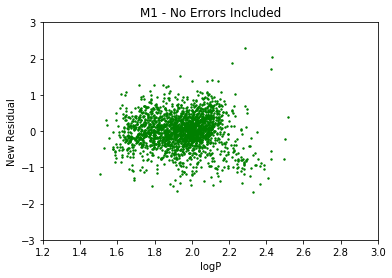

In [164]:
# NewlogMdotCalc - logMdotobs vs logP
xdataSet = logPData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logP')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logP")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(per_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logP')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 1.6705313899903649 + -0.46630555748488595 logL


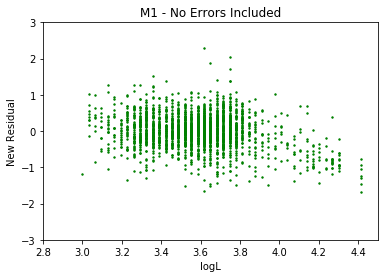

In [165]:
# NewlogMdotCalc - logMdotobs vs logL
xdataSet = logLData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logL')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logL")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(lum_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logL')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 1.0918107406226831 + 4.412117525322213 logQ


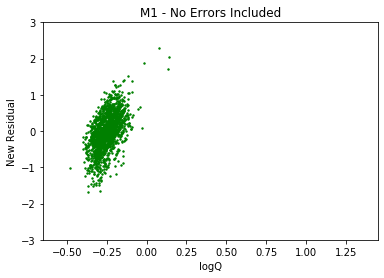

In [166]:
# NewlogMdotCalc - logMdotobs vs logQ (Q = (P/L^W))
logQData = np.log10(10**(logPData)/(10**(logLData))**(WRatio))

xdataSet = logQData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logQ')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlim(Q_limits)
plot.ylim(resid_limits)
plot.xlabel("logQ")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logQ')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 0.01066381489085751 + -1.7028114360542714 logM


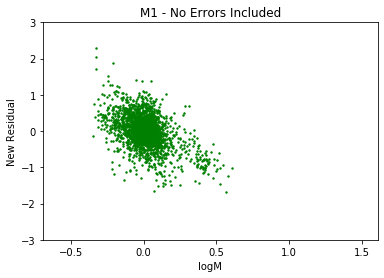

In [167]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logMData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logMData, ResidualYAxis, s=2, color='green')
plot.xlim(mass_limits)
plot.ylim(resid_limits)
plot.xlabel("logM")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logM')

## C0 Stars

In [168]:
DataToFit=C0StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.
#DataToFit = CriticalZoneOnly(DataToFit,-7,-6)
Percentile40th = int(np.floor(0.4*len(np.transpose(DataToFit))))
Percentile60th = int(np.ceil(0.6*len(np.transpose(DataToFit))))
print('40th Percentile:', Percentile40th,'60th Percentile:', Percentile60th)
DataToFit = MassRangeSelect (DataToFit, Percentile40th, Percentile60th )
# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logLDataError = np.log10(DataToFit[LErrorIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotDataError = np.log10(DataToFit[MdotErrorIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])

40th Percentile: 797 60th Percentile: 1197


In [169]:
#logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio)) # log (P/(L^W))

# logP ~ V + W log L

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLData
y = logPData

data = pandas.DataFrame({'logL': x0, 'logP': y})

# Fit the model
model = wls("logP ~ logL", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            WLS Regression Results                            
Dep. Variable:                   logP   R-squared:                       0.516
Model:                            WLS   Adj. R-squared:                  0.515
Method:                 Least Squares   F-statistic:                     424.3
Date:                Sat, 07 Nov 2020   Prob (F-statistic):           1.06e-64
Time:                        19:18:15   Log-Likelihood:                 548.70
No. Observations:                 400   AIC:                            -1093.
Df Residuals:                     398   BIC:                            -1085.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.9221      0.078     11.796      0.0

W= 0.41870953488462537
logP= 0.9221255886346236 + 0.41870953488462537 logL


Text(0.5, 1.0, 'C0 - logP = V + W logL')

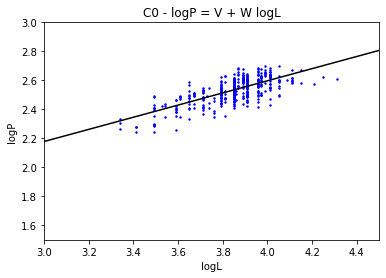

In [170]:
V = model._results.params[0]
WRatio = model._results.params[1]
print('W=',WRatio)
logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio)) # log (P/(L^W))

print('logP=', V, '+', WRatio, 'logL')
plot.scatter(logLData,logPData,s=2,color='blue')
coordinate_list = np.asarray([3,3.5,4,4.5])
logLvlogP_predict=V + WRatio *coordinate_list
plot.plot(coordinate_list,logLvlogP_predict, color='black')
plot.xlabel("logL")
plot.ylabel("logP")
plot.xlim(coordinate_list[0], coordinate_list[-1])
plot.ylim(1.5, 3)
plot.title('C0 - logP = V + W logL')

In [171]:
# Restore Unrestricted data so we can plot all of it, not just the data used to make our formula
DataToFit=C0StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.

# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logLDataError = np.log10(DataToFit[LErrorIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotDataError = np.log10(DataToFit[MdotErrorIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])
logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio)) # log (P/(L^W))

In [172]:
# logMdot ~ logA + c log((P/L)^W) + d logM

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPdivLWData
x1 = logMData
y = logMdotData

data = pandas.DataFrame({'logPdivLW': x0, 'logM': x1, 'logMdot': y})

# Fit the model
model = wls("logMdot ~ logPdivLW + logM", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            WLS Regression Results                            
Dep. Variable:                logMdot   R-squared:                       0.421
Model:                            WLS   Adj. R-squared:                  0.420
Method:                 Least Squares   F-statistic:                     722.7
Date:                Sat, 07 Nov 2020   Prob (F-statistic):          1.11e-236
Time:                        19:18:15   Log-Likelihood:                -598.15
No. Observations:                1994   AIC:                             1202.
Df Residuals:                    1991   BIC:                             1219.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -10.1835      0.103    -99.022      0.0

In [173]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logPdivLWData, logMData), y=logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[0]]) # Use the linear regression as an initial guess

# Run the regression.
outPdivLW_M = odr.run()

# Use the in-built pprint method to give us results.
outPdivLW_M.pprint()

logMdot_PdivLM = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2]
print( 'logMdot =', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM + ', outPdivLW_M.beta[2])


Beta: [  9.57196446   2.41789937 -15.7842378 ]
Beta Std Error: [0.26100471 0.12470989 0.25652711]
Beta Covariance: [[ 25.12248297   7.71548743 -24.61804991]
 [  7.71548743   5.73545215  -8.1254022 ]
 [-24.61804991  -8.1254022   24.26791263]]
Residual Variance: 0.0027116530719907823
Inverse Condition #: 0.004238190090587314
Reason(s) for Halting:
  Sum of squares convergence
logMdot = 9.571964457927034 log(P/L^W) +  2.4178993691909967 logM +  -15.784237799172608


In [174]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = logMdot_PdivLM

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_PdivLM': y})

# Fit the model
model = ols("logMdot_PdivLM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
PdivLMLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

Comparison to Observed: logMdot_calc = ( -0.09547095235283634 ) + ( 0.9852941326157518 )*logMdot_obsv


Text(0.5, 1.0, 'C0 - No Errors Included')

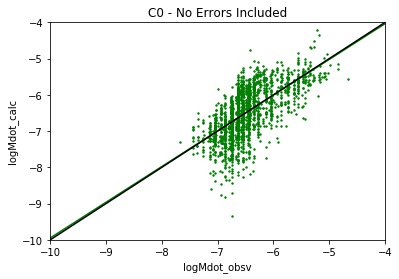

In [175]:
SlopeTestNoErrors=PdivLMLine[0] + PdivLMLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
print('Comparison to Observed:','logMdot_calc = (',PdivLMLine[0],') + (',PdivLMLine[1],')*logMdot_obsv')
plot.scatter(logMdotData, logMdot_PdivLM, s=2, color='green')
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('C0 - No Errors Included')

### Residuals

In [176]:
ResidualYAxis = logMdot_PdivLM - logMdotData # Calc - Obsv; Gives the distance between the regression line and the data
#ResidualYAxis = logMdot_PdivLM - ResidualYAxis # Subtract Residual from model
ylabel = 'First Residual' # What is on the y label until we change this value
star_type = 'C0'
PlotTitle = star_type + ' - No Errors Included' # Label the plot with whatever data set we are using

In [177]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPData
y = ResidualYAxis

data = pandas.DataFrame({'logPData': x0, 'ResidualYAxis': y})

# Fit the model
model = ols("ResidualYAxis ~ logPData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
ResidualsFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Residual Fit: logMdotCalc-logMdotObsv =', ResidualsFit[0], '+', ResidualsFit[1], 'logP')

Residual Fit: logMdotCalc-logMdotObsv = -9.825574748121028 + 3.8971993666460527 logP


#### Plot Set: First Residual vs logP, logL, logQ, and logM

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -9.825574748121028 + 3.8971993666460527 logP


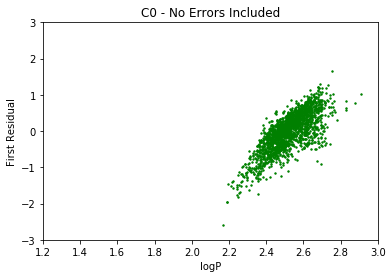

In [178]:
# NewlogMdotCalc - logMdotobs vs logP
xdataSet = logPData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logP')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logP")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(per_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_logP')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -4.869695401592185 + 1.2801243843783556 logL


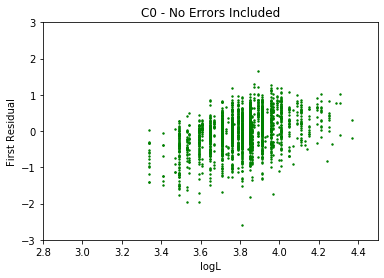

In [179]:
# NewlogMdotCalc - logMdotobs vs logL
xdataSet = logLData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logL')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logL")
plot.ylabel(ylabel)
plot.xlim(lum_limits)
plot.ylim(resid_limits)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_logL')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -4.0997857167148775 + 4.416044615556374 logQ


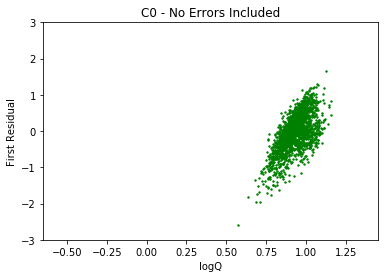

In [180]:
# NewlogMdotCalc - logMdotobs vs logQ (Q = (P/L^W))
logQData = np.log10(10**(logPData)/(10**(logLData))**(WRatio))

xdataSet = logQData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logQ')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logQ")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(Q_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_logQ')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -0.07405406497256747 + 0.44129722191556786 logM


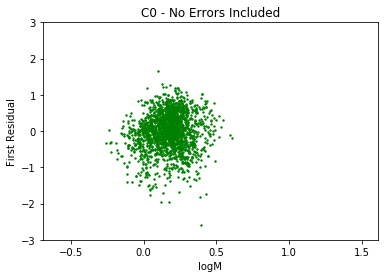

In [181]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logMData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logMData, ResidualYAxis, s=2, color='green')
plot.xlabel("logM")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(mass_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_logM')

In [182]:
NewMdotCalc = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2] - ResidualsFit[0] - ResidualsFit[1]*logPData
ylabel = "NewlogMdotCalc"
print('NewMdotCalc =', -ResidualsFit[0] + outPdivLW_M.beta[2], '+', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM - ', ResidualsFit[1], 'logP', '; W =', WRatio )
print('NewMdotCalc =', -ResidualsFit[0] + outPdivLW_M.beta[2], '+ (', outPdivLW_M.beta[0] - ResidualsFit[1],') logP + (', -1*outPdivLW_M.beta[0]*WRatio,') logL + ', outPdivLW_M.beta[1], 'logM'  )

NewMdotCalc = -5.95866305105158 + 9.571964457927034 log(P/L^W) +  2.4178993691909967 logM -  3.8971993666460527 logP ; W = 0.41870953488462537
NewMdotCalc = -5.95866305105158 + ( 5.674765091280982 ) logP + ( -4.007872786110794 ) logL +  2.4178993691909967 logM


NewMdotCalc Fit: NewlogMdotCalc = -3.4259308154469776 + 0.47228670079044455 logMdot_obsv


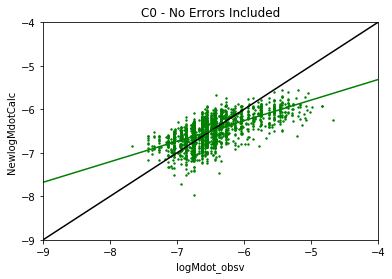

In [183]:
# logMdot ~ logM + logL + logP
xdataSet = logMdotData
# First we need to flatten the data: it's 2D layout is not relevent.
x0 = xdataSet
y = NewMdotCalc

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('NewMdotCalc Fit: NewlogMdotCalc =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logMdot_obsv')

plot.scatter(xdataSet, NewMdotCalc, s=2, color='green')
plot.plot(np.asarray([-9,-7,-6,-4]),np.asarray([-9,-7,-6,-4]),color='black')
SlopeTestNoErrors=NewMdotCalcFit[0] +NewMdotCalcFit[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.xlim(mdot_limits)
plot.ylim(mdot_limits)
plot.xlabel("logMdot_obsv")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/newMdot_vs_Mdotobsv')

Residuals Fit: OldResidual = -1.3274693089551648e-08 + 0.999999999999998 NewResidual


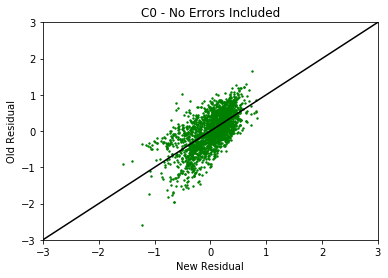

In [184]:
# 
NewResidual = NewMdotCalc - logMdotData # Calc - Obsv; Gives the distance between the regression line and the data
ylabel = 'Old Residual' # What is on the y label until we change this value

xdataSet = NewResidual
# First we need to flatten the data: it's 2D layout is not relevent.
x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Residuals Fit: OldResidual =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'NewResidual')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.plot(np.asarray([-4,-1,0,1,4]),np.asarray([-4,-1,0,1,4]),color='black')
plot.xlim(resid_limits)
plot.ylim(resid_limits)
plot.xlabel("New Residual")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_second_resid')

In [185]:
### RMS of Data
RMSE = calc_rms_error (NewMdotCalc, logMdotData)
print ('RMS Error:', RMSE)
print ('STD Dev:', np.std(NewMdotCalc))

RMS Error: 0.33346664567518064
STD Dev: 0.31779674369271743


#### Plot Set: New Residual vs logP, logL, logQ, and logM

In [186]:
ylabel = 'New Residual'
ResidualYAxis = NewResidual

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 5.495603971894525e-15 + -4.881511861398735e-15 logP


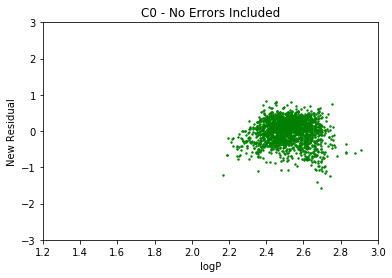

In [187]:
# NewlogMdotCalc - logMdotobs vs logP
xdataSet = logPData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logP')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logP")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(per_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logP')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 1.1999696873124346 + -0.31544282234340404 logL


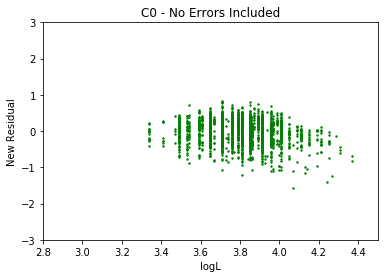

In [188]:
# NewlogMdotCalc - logMdotobs vs logL
xdataSet = logLData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logL')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logL")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(lum_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logL')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -0.5441851454478192 + 0.5861637790980313 logQ


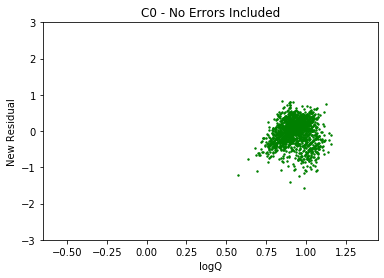

In [189]:
# NewlogMdotCalc - logMdotobs vs logQ (Q = (P/L^W))
logQData = np.log10(10**(logPData)/(10**(logLData))**(WRatio))

xdataSet = logQData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logQ')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlim(Q_limits)
plot.ylim(resid_limits)
plot.xlabel("logQ")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logQ')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 0.08840067216206267 + -0.5267905016156416 logM


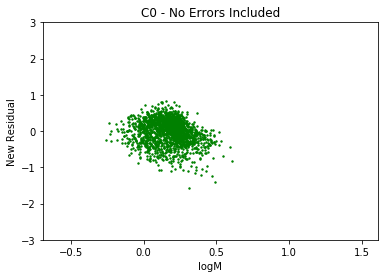

In [190]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logMData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logMData, ResidualYAxis, s=2, color='green')
plot.xlim(mass_limits)
plot.ylim(resid_limits)
plot.xlabel("logM")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logM')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -8.624721482905475 + 0.8818787883614391 logM


Text(0.5, 1.0, 'C0 - No Errors Included')

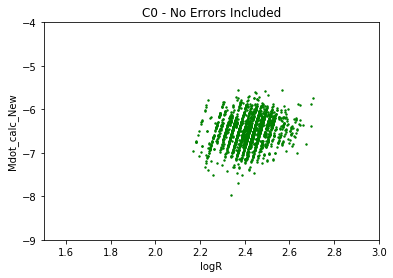

In [191]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logRData

x0 = xdataSet
y = NewMdotCalc

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logRData, NewMdotCalc, s=2, color='green')
plot.xlim(1.5,3)
plot.ylim(mdot_limits)
plot.xlabel("logR")
plot.ylabel('Mdot_calc_New')
plot.title(PlotTitle)
#plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logM')

## C1 Stars

In [192]:
DataToFit=C1StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.
#DataToFit = CriticalZoneOnly(DataToFit,-7,-6)
Percentile40th = int(np.floor(0.4*len(np.transpose(DataToFit))))
Percentile60th = int(np.ceil(0.6*len(np.transpose(DataToFit))))
print('40th Percentile:', Percentile40th,'60th Percentile:', Percentile60th)
DataToFit = MassRangeSelect (DataToFit, Percentile40th, Percentile60th )
# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logLDataError = np.log10(DataToFit[LErrorIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotDataError = np.log10(DataToFit[MdotErrorIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])

40th Percentile: 312 60th Percentile: 469


In [193]:
#logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio)) # log (P/(L^W))

# logP ~ V + W log L

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logLData
y = logPData

data = pandas.DataFrame({'logL': x0, 'logP': y})

# Fit the model
model = wls("logP ~ logL", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            WLS Regression Results                            
Dep. Variable:                   logP   R-squared:                       0.411
Model:                            WLS   Adj. R-squared:                  0.407
Method:                 Least Squares   F-statistic:                     108.0
Date:                Sat, 07 Nov 2020   Prob (F-statistic):           1.58e-19
Time:                        19:18:17   Log-Likelihood:                 234.82
No. Observations:                 157   AIC:                            -465.6
Df Residuals:                     155   BIC:                            -459.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.8003      0.138      5.791      0.0

W= 0.37085618916281626
logP= 0.8002687209340122 + 0.37085618916281626 logL


Text(0.5, 1.0, 'C1 - logP = V + W logL')

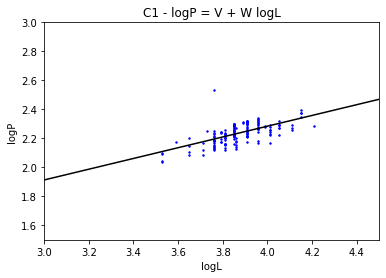

In [194]:
V = model._results.params[0]
WRatio = model._results.params[1]
print('W=',WRatio)
logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio)) # log (P/(L^W))

print('logP=', V, '+', WRatio, 'logL')
plot.scatter(logLData,logPData,s=2,color='blue')
coordinate_list = np.asarray([3,3.5,4,4.5])
logLvlogP_predict=V + WRatio *coordinate_list
plot.plot(coordinate_list,logLvlogP_predict, color='black')
plot.xlabel("logL")
plot.ylabel("logP")
plot.xlim(coordinate_list[0], coordinate_list[-1])
plot.ylim(1.5, 3)
plot.title('C1 - logP = V + W logL')

In [195]:
# Restore Unrestricted data so we can plot all of it, not just the data used to make our formula
DataToFit=C1StarData # Assign one of the data sets to a new variable. This will save some effort down the line and limit memory usage.

# Now take the columns we want from the data set and assign them to their own variables.
logMData = np.log10(DataToFit[MIndex]) 
logRData = np.log10(DataToFit[RIndex])
logLData = np.log10(DataToFit[LIndex])
logLDataError = np.log10(DataToFit[LErrorIndex])
logPData = np.log10(DataToFit[PIndex])
logMdotData = np.log10(DataToFit[MdotIndex])
logMdotDataError = np.log10(DataToFit[MdotErrorIndex])
logTeffObsvData = np.log10(DataToFit[TeffObsvIndex])
logTeffCalcData = np.log10(DataToFit[TeffCalcIndex])
logPdivLWData = np.log10((DataToFit[PIndex]/DataToFit[LIndex]**WRatio)) # log (P/(L^W))

In [196]:
# logMdot ~ logA + c log((P/L)^W) + d logM

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPdivLWData
x1 = logMData
y = logMdotData

data = pandas.DataFrame({'logPdivLW': x0, 'logM': x1, 'logMdot': y})

# Fit the model
model = wls("logMdot ~ logPdivLW + logM", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            WLS Regression Results                            
Dep. Variable:                logMdot   R-squared:                       0.382
Model:                            WLS   Adj. R-squared:                  0.381
Method:                 Least Squares   F-statistic:                     240.6
Date:                Sat, 07 Nov 2020   Prob (F-statistic):           4.58e-82
Time:                        19:18:18   Log-Likelihood:                 40.855
No. Observations:                 781   AIC:                            -75.71
Df Residuals:                     778   BIC:                            -61.73
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -9.0410      0.109    -83.227      0.0

In [197]:
# Define a function (four-variable linear in our case) to fit the data with.
def fitting_func(B, x):
    return B[0]*x[0] + B[1]*x[1] + B[2] # A simple linear fit

# Create a model for fitting.
linear_model = Model(fitting_func)

# Create a RealData object using our initiated data from above.
data = RealData((logPdivLWData, logMData), y=logMdotData) # Data: x=logL, y=logR

# Set up ODR with the model and data.
odr = ODR(data, linear_model, beta0=[model._results.params[1],model._results.params[2],model._results.params[0]]) # Use the linear regression as an initial guess

# Run the regression.
outPdivLW_M = odr.run()

# Use the in-built pprint method to give us results.
outPdivLW_M.pprint()

logMdot_PdivLM = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2]
print( 'logMdot =', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM + ', outPdivLW_M.beta[2])


Beta: [  7.14200795   2.4036843  -12.7532376 ]
Beta Std Error: [0.31938374 0.16080781 0.27250098]
Beta Covariance: [[ 44.25610929  14.58629786 -37.61276418]
 [ 14.58629786  11.21920019 -13.45977482]
 [-37.61276418 -13.45977482  32.21690046]]
Residual Variance: 0.0023049015270770724
Inverse Condition #: 0.005810740914410059
Reason(s) for Halting:
  Sum of squares convergence
logMdot = 7.142007947003209 log(P/L^W) +  2.403684298376941 logM +  -12.753237599236027


In [198]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logMdotData
y = logMdot_PdivLM

data = pandas.DataFrame({'logMdotData': x0, 'logMdot_PdivLM': y})

# Fit the model
model = ols("logMdot_PdivLM ~ logMdotData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
PdivLMLine = model._results.params # Defines the quality-of-fit line with array (intercept, slope)

Comparison to Observed: logMdot_calc = ( -0.1795794608954967 ) + ( 0.9730970128239868 )*logMdot_obsv


Text(0.5, 1.0, 'C1 - No Errors Included')

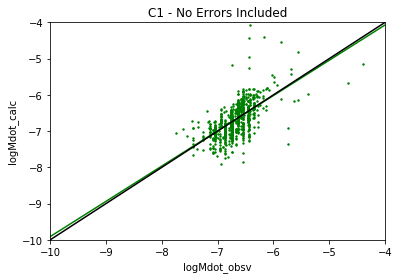

In [199]:
SlopeTestNoErrors=PdivLMLine[0] + PdivLMLine[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
print('Comparison to Observed:','logMdot_calc = (',PdivLMLine[0],') + (',PdivLMLine[1],')*logMdot_obsv')
plot.scatter(logMdotData, logMdot_PdivLM, s=2, color='green')
#plot.scatter(logMdotData, logMdot_LP_StdErrors, s=2)
#plot.scatter(logMdotData, logMdot_LP_RealErrors, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR, s=2)
#plot.scatter(logMdotData, logMdot_LPM_ODR_2, s=2)
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),color='black')
plot.xlabel("logMdot_obsv")
plot.ylabel("logMdot_calc")
plot.xlim(-10, -4)
plot.ylim(-10, -4)
plot.title('C1 - No Errors Included')

### Residuals

In [200]:
ResidualYAxis = logMdot_PdivLM - logMdotData # Calc - Obsv; Gives the distance between the regression line and the data
#ResidualYAxis = logMdot_PdivLM - ResidualYAxis # Subtract Residual from model
ylabel = 'First Residual' # What is on the y label until we change this value
star_type = 'C1'
PlotTitle = star_type + ' - No Errors Included' # Label the plot with whatever data set we are using

In [201]:
# logMdot ~ logM + logL + logP

# First we need to flatten the data: it's 2D layout is not relevent.
x0 = logPData
y = ResidualYAxis

data = pandas.DataFrame({'logPData': x0, 'ResidualYAxis': y})

# Fit the model
model = ols("ResidualYAxis ~ logPData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
ResidualsFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Residual Fit: logMdotCalc-logMdotObsv =', ResidualsFit[0], '+', ResidualsFit[1], 'logP')

Residual Fit: logMdotCalc-logMdotObsv = -6.589034994096469 + 2.955133692683276 logP


#### Plot Set: First Residual vs logP, logL, logQ, and logM

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -6.589034994096469 + 2.955133692683276 logP


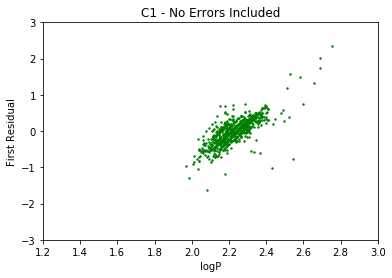

In [202]:
# NewlogMdotCalc - logMdotobs vs logP
xdataSet = logPData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logP')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logP")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(per_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_logP')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -5.458287658454416 + 1.411163676795371 logL


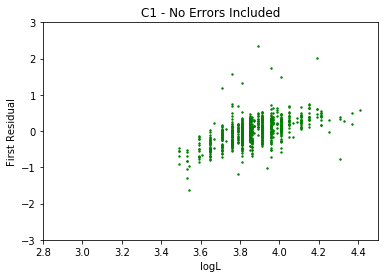

In [203]:
# NewlogMdotCalc - logMdotobs vs logL
xdataSet = logLData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logL')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logL")
plot.ylabel(ylabel)
plot.xlim(lum_limits)
plot.ylim(resid_limits)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_logL')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -2.633358394072414 + 3.311384956683115 logQ


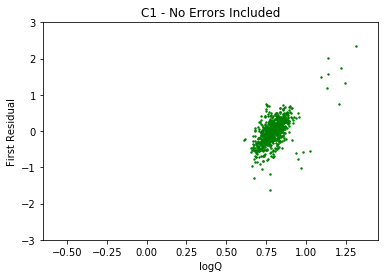

In [204]:
# NewlogMdotCalc - logMdotobs vs logQ (Q = (P/L^W))
logQData = np.log10(10**(logPData)/(10**(logLData))**(WRatio))

xdataSet = logQData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logQ')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logQ")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(Q_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_logQ')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -0.07773332685161935 + 0.4688460192885994 logM


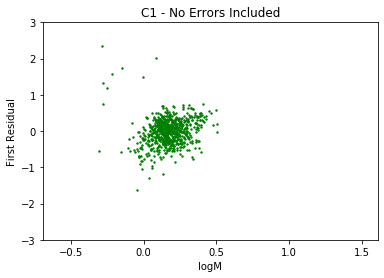

In [205]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logMData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logMData, ResidualYAxis, s=2, color='green')
plot.xlabel("logM")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(mass_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_logM')

In [206]:
NewMdotCalc = outPdivLW_M.beta[0]*logPdivLWData + outPdivLW_M.beta[1]*logMData + outPdivLW_M.beta[2] - ResidualsFit[0] - ResidualsFit[1]*logPData
ylabel = "NewlogMdotCalc"
print('NewMdotCalc =', -ResidualsFit[0] + outPdivLW_M.beta[2], '+', outPdivLW_M.beta[0], 'log(P/L^W) + ', outPdivLW_M.beta[1], 'logM - ', ResidualsFit[1], 'logP', '; W =', WRatio )
print('NewMdotCalc =', -ResidualsFit[0] + outPdivLW_M.beta[2], '+ (', outPdivLW_M.beta[0] - ResidualsFit[1],') logP + (', -1*outPdivLW_M.beta[0]*WRatio,') logL + ', outPdivLW_M.beta[1], 'logM'  )

NewMdotCalc = -6.1642026051395575 + 7.142007947003209 log(P/L^W) +  2.403684298376941 logM -  2.955133692683276 logP ; W = 0.37085618916281626
NewMdotCalc = -6.1642026051395575 + ( 4.186874254319933 ) logP + ( -2.648657850196159 ) logL +  2.403684298376941 logM


NewMdotCalc Fit: NewlogMdotCalc = -4.138816936183048 + 0.37995956761237143 logMdot_obsv


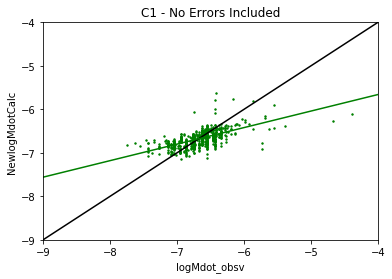

In [207]:
# logMdot ~ logM + logL + logP
xdataSet = logMdotData
# First we need to flatten the data: it's 2D layout is not relevent.
x0 = xdataSet
y = NewMdotCalc

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('NewMdotCalc Fit: NewlogMdotCalc =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logMdot_obsv')

plot.scatter(xdataSet, NewMdotCalc, s=2, color='green')
plot.plot(np.asarray([-9,-7,-6,-4]),np.asarray([-9,-7,-6,-4]),color='black')
SlopeTestNoErrors=NewMdotCalcFit[0] +NewMdotCalcFit[1] *(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]))
plot.plot(np.asarray([-10,-9,-8,-7,-6,-5,-4,-3]),SlopeTestNoErrors, color='green')
plot.xlim(mdot_limits)
plot.ylim(mdot_limits)
plot.xlabel("logMdot_obsv")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/newMdot_vs_Mdotobsv')

Residuals Fit: OldResidual = 1.9960666154889353e-08 + 0.9999999999999999 NewResidual


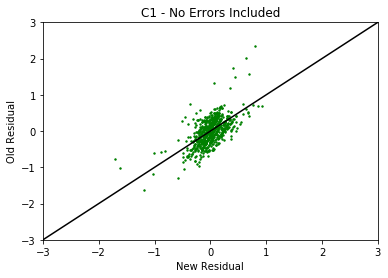

In [208]:
# 
NewResidual = NewMdotCalc - logMdotData # Calc - Obsv; Gives the distance between the regression line and the data
ylabel = 'Old Residual' # What is on the y label until we change this value

xdataSet = NewResidual
# First we need to flatten the data: it's 2D layout is not relevent.
x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary
#print(model.summary())

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Residuals Fit: OldResidual =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'NewResidual')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.plot(np.asarray([-4,-1,0,1,4]),np.asarray([-4,-1,0,1,4]),color='black')
plot.xlim(resid_limits)
plot.ylim(resid_limits)
plot.xlabel("New Residual")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/first_resid_vs_second_resid')

In [209]:
### RMS of Data
RMSE = calc_rms_error (NewMdotCalc, logMdotData)
print ('RMS Error:', RMSE)
print ('STD Dev:', np.std(NewMdotCalc))

RMS Error: 0.22977767194778145
STD Dev: 0.17974335774051226


#### Plot Set: New Residual vs logP, logL, logQ, and logM

In [210]:
ylabel = 'New Residual'
ResidualYAxis = NewResidual

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -1.097131283392394e-15 + -3.7194910779830836e-16 logP


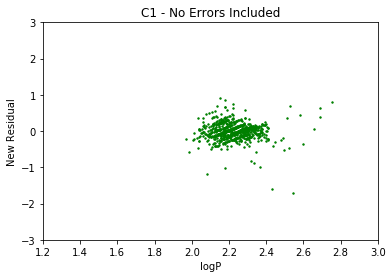

In [211]:
# NewlogMdotCalc - logMdotobs vs logP
xdataSet = logPData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logP')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logP")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(per_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logP')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -0.15681886498706143 + 0.0405433167220445 logL


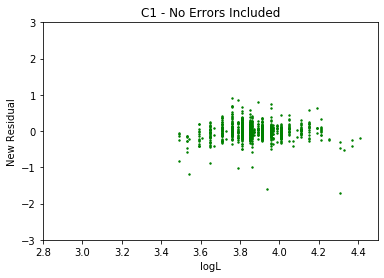

In [212]:
# NewlogMdotCalc - logMdotobs vs logL
xdataSet = logLData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logL')


plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlabel("logL")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.xlim(lum_limits)
plot.ylim(resid_limits)
plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logL')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = 0.04905537567068323 + -0.06168595667597048 logQ


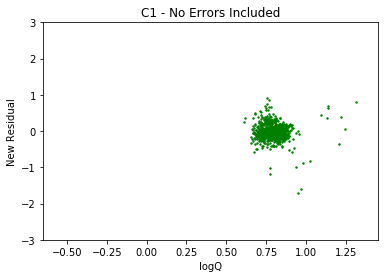

In [213]:
# NewlogMdotCalc - logMdotobs vs logQ (Q = (P/L^W))
logQData = np.log10(10**(logPData)/(10**(logLData))**(WRatio))

xdataSet = logQData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logQ')

plot.scatter(xdataSet, ResidualYAxis, s=2, color='green')
plot.xlim(Q_limits)
plot.ylim(resid_limits)
plot.xlabel("logQ")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logQ')

Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv = -0.01207983372622283 + 0.07285910344094058 logM


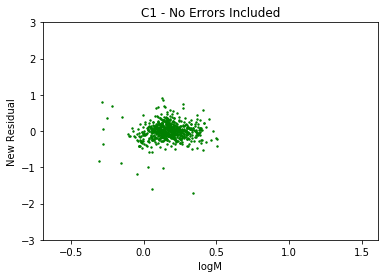

In [214]:
# NewlogMdotCalc - logMdotobs vs logM

xdataSet = logMData

x0 = xdataSet
y = ResidualYAxis

data = pandas.DataFrame({'fittingData': x0, 'NewMdotCalc': y})

# Fit the model
model = ols("NewMdotCalc ~ fittingData", data).fit()

# Print the summary

#print("\nRetrieving manually the parameter estimates:")
#print(model._results.params)
NewMdotCalcFit = model._results.params # Defines the quality-of-fit line with array (intercept, slope)
print('Resid. vs Parameter Fit: logMdot_calc - logMdot_obsv =', NewMdotCalcFit[0], '+', NewMdotCalcFit[1], 'logM')

plot.scatter(logMData, ResidualYAxis, s=2, color='green')
plot.xlim(mass_limits)
plot.ylim(resid_limits)
plot.xlabel("logM")
plot.ylabel(ylabel)
plot.title(PlotTitle)
plot.savefig('Residual_Images/Q/'+star_type+'/second_resid_vs_logM')